In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [2]:
#loading from where we left in the feature generation notebook
train_Set = pd.read_csv(r"C:\Project\Research-Project\DataFrame_Extracts\train_New.csv")
test_Set  = pd.read_csv(r"C:\Project\Research-Project\DataFrame_Extracts\test_New.csv")


In [3]:
# checking for empty rows or for NaNs as we don't want surprises durin the hours long trainning 
nan_rows = train_Set[train_Set.isna().any(axis=1)]

# Loop through and print the exact missing columns for each row
for idx, row in nan_rows.iterrows():
    # Identify which columns are null in this specific row
    missing_cols = row[row.isna()].index.tolist()
    print(f"Row index {idx} is missing values in columns: {missing_cols}")

Row index 296 is missing values in columns: ['mean', 'mode']
Row index 302 is missing values in columns: ['mean', 'mode']
Row index 1059 is missing values in columns: ['mean', 'mode']
Row index 1193 is missing values in columns: ['mean', 'mode']
Row index 1986 is missing values in columns: ['mean', 'mode']
Row index 2314 is missing values in columns: ['mean', 'mode']
Row index 2370 is missing values in columns: ['mean', 'mode']
Row index 2604 is missing values in columns: ['mean', 'mode']
Row index 3229 is missing values in columns: ['mean', 'mode']
Row index 3230 is missing values in columns: ['mean', 'mode']
Row index 4766 is missing values in columns: ['mean', 'mode']
Row index 4908 is missing values in columns: ['mean', 'mode']
Row index 5279 is missing values in columns: ['mean', 'mode']
Row index 5294 is missing values in columns: ['mean', 'mode']
Row index 5487 is missing values in columns: ['mean', 'mode']
Row index 5703 is missing values in columns: ['mean', 'mode']
Row index 

In [4]:
# we're CLEANING i.e. dropping NaNs from the TRAINING set
train_Set = train_Set.dropna(axis=0)

# we're CLEANING i.e. dropping NaNs from the TEST set
test_Set = test_Set.dropna(axis=0)
 

In [5]:
cols_to_standardize = [   # of columns that contains our math 
    'mean', 'mode', 'rmssd', 'pnn50', 'total', 
    'poincare_sd1', 'poincare_sd2', 'poincare_ratio', 'poincare_area', 
    'var_sdrr_straight', 'var_sdnn_approx', 'var_sdnn_interp', 'qa_raw_length',
    'qa_interp_beats', 'qa_noise_count', 'qa_ectopic_count',
    'qa_missed_beat_count'
    #, 'qa_has_ectopics', 'qa_has_missed' # we're not scaling these 2 cols are theya re boolean and Neural network will handle these colums easily
]

new_feature_cols = [   # of columns that contains our math 
    'mean', 'mode', 'rmssd', 'pnn50', 'total', 
    'poincare_sd1', 'poincare_sd2', 'poincare_ratio', 'poincare_area', 
    'var_sdrr_straight', 'var_sdnn_approx', 'var_sdnn_interp', 'qa_raw_length',
    'qa_interp_beats', 'qa_noise_count', 'qa_ectopic_count',
    'qa_missed_beat_count',
    'qa_has_ectopics', 'qa_has_missed' # we're not scaling these 2 cols are theya re boolean and Neural network will handle these colums easily
]

# 2. Print them cleanly using a multi-line triple-quoted f-string
print(f"""All cols : {train_Set.columns} 
Cols to standardize : {cols_to_standardize}""")

All cols : Index(['Unnamed: 0', 'SampleID', 'Inference', 'Matlab_files',
       'Sampling_Rate_Hz', 'Signal_Length_Samples', 'Num_Channels', 'Units',
       'Sliced_SampleID', 'Start_Idx', 'End_Idx', 'PQRST_Points', 'R_Peaks',
       'mean', 'mode', 'rmssd', 'pnn50', 'total', 'poincare_sd1',
       'poincare_sd2', 'poincare_ratio', 'poincare_area', 'var_sdrr_straight',
       'var_sdnn_approx', 'var_sdnn_interp', 'qa_raw_length',
       'qa_interp_beats', 'qa_noise_count', 'qa_ectopic_count',
       'qa_missed_beat_count', 'qa_has_ectopics', 'qa_has_missed'],
      dtype='object') 
Cols to standardize : ['mean', 'mode', 'rmssd', 'pnn50', 'total', 'poincare_sd1', 'poincare_sd2', 'poincare_ratio', 'poincare_area', 'var_sdrr_straight', 'var_sdnn_approx', 'var_sdnn_interp', 'qa_raw_length', 'qa_interp_beats', 'qa_noise_count', 'qa_ectopic_count', 'qa_missed_beat_count']


In [6]:
train_Set[cols_to_standardize]

,mean,mode,rmssd,pnn50,total,poincare_sd1,poincare_sd2,poincare_ratio,poincare_area,var_sdrr_straight,var_sdnn_approx,var_sdnn_interp,qa_raw_length,qa_interp_beats,qa_noise_count,qa_ectopic_count,qa_missed_beat_count
0,1340.000000,1110.0,396.754892,90.000000,21,280.548075,232.487526,1.206723,204907.012436,257.640905,135.378258,203.174650,21.0,16.0,5.0,1.0,0.0
1,802.162162,810.0,41.047248,11.111111,37,29.024787,57.000989,0.509198,5197.581493,45.230250,38.812977,45.230250,37.0,37.0,0.0,0.0,0.0
2,852.666667,860.0,135.336666,35.294118,35,95.697474,124.960285,0.765823,37568.370159,111.294832,61.192000,63.538289,35.0,31.0,4.0,0.0,0.0
3,790.360360,750.0,374.427547,88.888889,37,264.760257,197.568413,1.340094,164331.257801,233.592885,64.547863,79.203163,37.0,33.0,6.0,2.0,2.0
4,967.888889,980.0,195.582439,86.206897,30,138.297669,75.397886,1.834238,32758.492020,111.380174,71.888441,82.771148,30.0,28.0,2.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6784,1096.419753,1100.0,576.737805,88.461538,27,168.728686,127.840299,1.319840,67765.176781,149.687193,70.035617,70.582433,38.0,34.0,4.0,1.0,0.0
6785,688.571429,680.0,16.095918,0.000000,42,4.265495,4.910032,0.868730,65.796626,4.599068,4.599068,4.599068,41.0,41.0,0.0,0.0,0.0
6786,814.629630,810.0,2.760262,0.000000,36,33.427644,57.146004,0.584952,6001.247160,46.813850,46.813850,46.813850,31.0,31.0,0.0,0.0,0.0
6787,813.055556,810.0,3.137080,0.000000,36,16.180407,30.312575,0.533785,1540.856294,24.296685,24.296685,24.296685,25.0,25.0,0.0,0.0,0.0


In [7]:
# need to do a pit of preprocessing with our newely created features before we feed it to the model 
# for example we need to normalise/standardize it 

 
scaler = StandardScaler()

# 1. Pass only the listed columns to fit and transform
X_train_scaled_parts = scaler.fit_transform(train_Set[cols_to_standardize])

# 2. Pass only the listed columns to transform the test set
X_test_scaled_parts = scaler.transform(test_Set[cols_to_standardize])
 
# 3. Overwrite the original columns with the new scaled values
train_Set[cols_to_standardize] = X_train_scaled_parts
test_Set[cols_to_standardize] = X_test_scaled_parts

In [8]:
train_Set

,Unnamed: 0,SampleID,Inference,Matlab_files,Sampling_Rate_Hz,Signal_Length_Samples,Num_Channels,Units,Sliced_SampleID,Start_Idx,...,var_sdrr_straight,var_sdnn_approx,var_sdnn_interp,qa_raw_length,qa_interp_beats,qa_noise_count,qa_ectopic_count,qa_missed_beat_count,qa_has_ectopics,qa_has_missed
0,0,A03095,O,C:\Project\Research-Project\training2017\\A03095,300,9000,1,mV,A03095_1,0,...,1.588959,3.581669,4.887325,-1.738429,-1.166039,-0.018073,0.564204,-0.260601,1.0,0.0
1,1,A03688,N,C:\Project\Research-Project\training2017\\A03688,300,13398,1,mV,A03688_1,0,...,-0.611708,0.085610,0.093872,0.314350,0.518049,-0.518617,-0.381351,-0.260601,0.0,0.0
2,2,A07992,O,C:\Project\Research-Project\training2017\\A07992,300,9000,1,mV,A07992_1,0,...,0.072750,0.895822,0.649502,0.057752,0.036881,-0.118181,-0.381351,-0.260601,0.0,0.0
3,3,A06423,A,C:\Project\Research-Project\training2017\\A06423,300,9000,1,mV,A06423_1,0,...,1.339811,1.017318,1.124916,0.314350,0.197270,0.082036,1.509758,0.184574,1.0,1.0
4,4,A07892,O,C:\Project\Research-Project\training2017\\A07892,300,9000,1,mV,A07892_1,0,...,0.073634,1.283077,1.233200,-0.583741,-0.203703,-0.318399,0.564204,-0.260601,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6784,6784,A00114,O,C:\Project\Research-Project\training2017\\A00114,300,9000,1,mV,A00114_1,0,...,0.470512,1.215998,0.863285,0.442649,0.277465,-0.118181,0.564204,-0.260601,1.0,0.0
6785,6785,A05942,O,C:\Project\Research-Project\training2017\\A05942,300,12204,1,mV,A05942_1,0,...,-1.032664,-1.153074,-1.139243,0.827545,0.838828,-0.518617,-0.381351,-0.260601,0.0,0.0
6786,6786,A05613,N,C:\Project\Research-Project\training2017\\A05613,300,14104,1,mV,A05613_1,0,...,-0.595301,0.375274,0.141933,-0.455442,0.036881,-0.518617,-0.381351,-0.260601,0.0,0.0
6787,6787,A05613,N,C:\Project\Research-Project\training2017\\A05613,300,14104,1,mV,A05613_2,5104,...,-0.828588,-0.439939,-0.541441,-1.225235,-0.444287,-0.518617,-0.381351,-0.260601,0.0,0.0


In [9]:
test_Set.head(1)

,Unnamed: 0,SampleID,Inference,Matlab_files,Sampling_Rate_Hz,Signal_Length_Samples,Num_Channels,Units,Sliced_SampleID,Start_Idx,...,var_sdrr_straight,var_sdnn_approx,var_sdnn_interp,qa_raw_length,qa_interp_beats,qa_noise_count,qa_ectopic_count,qa_missed_beat_count,qa_has_ectopics,qa_has_missed
0,0,A00976,N,C:\Project\Research-Project\training2017\\A00976,300,9000,1,mV,A00976_1,0,...,-0.824485,-0.425602,-0.529422,0.827545,0.838828,-0.518617,-0.381351,-0.260601,0.0,0.0


In [10]:
train_Set.head(1)

,Unnamed: 0,SampleID,Inference,Matlab_files,Sampling_Rate_Hz,Signal_Length_Samples,Num_Channels,Units,Sliced_SampleID,Start_Idx,...,var_sdrr_straight,var_sdnn_approx,var_sdnn_interp,qa_raw_length,qa_interp_beats,qa_noise_count,qa_ectopic_count,qa_missed_beat_count,qa_has_ectopics,qa_has_missed
0,0,A03095,O,C:\Project\Research-Project\training2017\\A03095,300,9000,1,mV,A03095_1,0,...,1.588959,3.581669,4.887325,-1.738429,-1.166039,-0.018073,0.564204,-0.260601,1.0,0.0


In [11]:
#from tensorflow.keras import layers, models
#
#model_1d = models.Sequential([
#    # Block 1: Catching raw features
#    layers.Conv1D(filters=32, kernel_size=7, activation='relu', input_shape=(9000, 1)),
#    layers.BatchNormalization(),
#    layers.MaxPooling1D(pool_size=4), # Downsample aggressive early on
#    
#    # Block 2: Middle-level patterns
#    layers.Conv1D(filters=64, kernel_size=5, activation='relu'),
#    layers.BatchNormalization(),
#    layers.MaxPooling1D(pool_size=4),
#    
#    # Block 3: Deep contextual patterns
#    layers.Conv1D(filters=128, kernel_size=3, activation='relu'),
#    layers.BatchNormalization(),
#    layers.MaxPooling1D(pool_size=4), # Your sequence is now compressed perfectly
#    
#    # The Global Bottleneck
#    layers.GlobalAveragePooling1D(),
#    layers.Dropout(0.5),
#
#    # Classifier Head
#    layers.Dense(64, activation='relu'),
#    layers.Dense(4, activation='softmax')
#])
#
#model_1d.summary()

In [12]:
#model_1d.compile( optimizer='adam', 
#               loss='sparse_categorical_crossentropy', 
#               metrics=['accuracy'],
#                run_eagerly=True # to pinpoint the Error 
#                )

In [13]:
import tensorflow as tf
from tensorflow.keras import layers, models

# ==========================================
# BRANCH 1: The Raw Signal CNN (Your original architecture)
# ==========================================
signal_input = layers.Input(shape=(9000, 1), name="raw_signal_input")

x1 = layers.Conv1D(filters=32, kernel_size=7, activation='relu')(signal_input)
x1 = layers.BatchNormalization()(x1)
x1 = layers.MaxPooling1D(pool_size=4)(x1)

x1 = layers.Conv1D(filters=64, kernel_size=5, activation='relu')(x1)
x1 = layers.BatchNormalization()(x1)
x1 = layers.MaxPooling1D(pool_size=4)(x1)

x1 = layers.Conv1D(filters=128, kernel_size=3, activation='relu')(x1)
x1 = layers.BatchNormalization()(x1)
x1 = layers.MaxPooling1D(pool_size=4)(x1)

cnn_output = layers.GlobalAveragePooling1D()(x1)

# ==========================================
# BRANCH 2: The Engineered HRV Features MLP
# ==========================================
hrv_input = layers.Input(shape=(19,), name="hrv_features_input")

x2 = layers.Dense(32, activation='relu')(hrv_input)
x2 = layers.BatchNormalization()(x2)
mlp_output = layers.Dropout(0.3)(x2)

# ==========================================
# COMBINE BRANCHES & CLASSIFY
# ==========================================
# Merge the deep signal patterns with your explicit math metrics
combined = layers.concatenate([cnn_output, mlp_output])

# Shared Classifier Head
x = layers.Dense(64, activation='relu')(combined)
x = layers.Dropout(0.5)(x)
final_output = layers.Dense(4, activation='softmax', name="output")(x)

# Define the multi-input model
model_hybrid = models.Model(inputs=[signal_input, hrv_input], outputs=final_output)


In [14]:
model_hybrid.compile(
    optimizer='adam', 
    loss='sparse_categorical_crossentropy', 
    metrics=['accuracy'],
    run_eagerly=True # <--- Keep this active for your first test run!
)

In [15]:
#we took this function from our previous model, we gotta change it as now we're feeding the model out newely created d
import wfdb

def get_exact_1d_ecg_input(matlab_filepath, start_idx, end_idx):
    """
    Reads a raw MATLAB/WFDB signal from disk and cuts it precisely 
    between start_idx and end_idx using coordinates from the slicing dataframe.
    """
    # Clean file extensions if present
    record_path = str(matlab_filepath).replace('.mat', '').replace('.hea', '')
    
    try:
        # 1. Read raw voltage signals
        record = wfdb.rdrecord(record_path)
        signal = record.p_signal 
        
        # Pull the primary single lead channel (Lead I)
        lead_data = signal[:, 0]
        
        # 2. Slice the signal dynamically using your pipeline's markers
        # Explicit conversion to integers prevents indexing bugs
        sliced_data = lead_data[int(start_idx) : int(end_idx)]
        
        # 3. Safety Check: Verify the sliced segment is exactly 9000 points
        if len(sliced_data) != 9000:
            raise ValueError(
                f"Sliced length is {len(sliced_data)}, expected exactly 9000. "
                f"(Total file length: {len(lead_data)}, Indices: {start_idx} to {end_idx})"
            )
            
        # 4. Add the required Keras channel dimension and cast to float32
        # Transforms shape from (9000,) to (9000, 1)
        cnn_input_1d = np.expand_dims(sliced_data, axis=-1).astype('float32')
        
        return cnn_input_1d

    except Exception as e:
        print(f"🚨 Skipping record {record_path} due to error: {e}")
        return None

In [16]:
def data_generator(df, path_col, label_col, new_feature_cols):
    label_mapping = {'N': 0, 'A': 1, 'O': 2, '~': 3}
    
    for _, row in df.iterrows():
        file_path = row[path_col]
        raw_label = row[label_col]  
        
        label = label_mapping.get(raw_label, -1)
        if label == -1:
            continue  # Skip unexpected classes  
            
        start_w = row['Start_Idx']
        end_w = row['End_Idx']
        
        ecg_signal = get_exact_1d_ecg_input(file_path, start_w, end_w) 

        if ecg_signal is None:
            continue
        
        # Extract the 19 HRV features as a float32 vector
        hrv_vector = row[new_feature_cols].values.astype('float32')
        
        # FIX: Yield 'label' (the integer) instead of row[label_col] (the string)
        yield {"raw_signal_input": ecg_signal, "hrv_features_input": hrv_vector}, label




In [17]:
import tensorflow as tf
 
#def create_ecg_dataset(df, path_col, label_col, batch_size=32, shuffle=True):
#    
#    # Shuffling happens ONLY here, controlled completely by the 'shuffle' flag
#    current_df = df.sample(frac=1).reset_index(drop=True) if shuffle else df
#
#    dataset = tf.data.Dataset.from_generator(
#        generator=lambda: data_generator(current_df, path_col, label_col, new_feature_cols),
#        output_signature=(
#            tf.TensorSpec(shape=(9000, 1), dtype=tf.float32), 
#            tf.TensorSpec(shape=(), dtype=tf.int32)           
#        )
#    )
#    
#    dataset = dataset.batch(batch_size)
#    dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)
#    
#    return dataset

def create_hybrid_dataset(df, path_col, label_col, batch_size=32, shuffle=True):
    current_df = df.sample(frac=1).reset_index(drop=True) if shuffle else df

    dataset = tf.data.Dataset.from_generator(
        generator=lambda: data_generator(current_df, path_col, label_col, new_feature_cols),
        output_signature=(
            # Dictionary matching our Hybrid Model input names
            {
                "raw_signal_input": tf.TensorSpec(shape=(9000, 1), dtype=tf.float32), 
                "hrv_features_input": tf.TensorSpec(shape=(19,), dtype=tf.float32)
            },
            # The target label remains a flat integer
            tf.TensorSpec(shape=(), dtype=tf.int32)           
        )
    )
    
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)
    
    return dataset


In [18]:
from tensorflow.keras.callbacks import ModelCheckpoint

# Set up the auto-save configuration so taht in the event of a readbump, we don't loose 2+ hours of trainning

checkpoint_File = 'C:\Project\Research-Project\Models\ecg_model_checkpoint_V1.1.4.h5' 
checkpoint_callback = ModelCheckpoint(
    filepath=checkpoint_File,             # The file path where it saves to disk
    monitor='val_loss',                   # Look at validation loss to judge performance
    save_best_only=True,                  # ONLY overwrite the file if the model improved!
    mode='min',                           # We want the lowest possible validation loss
    verbose=1                             # Print a message whenever it auto-saves
)

In [19]:
# Create the hybrid pipelines
train_dataset_hybrid = create_hybrid_dataset(train_Set, 'Matlab_files', 'Inference', batch_size=32, shuffle=True)
val_dataset_hybrid   = create_hybrid_dataset(test_Set, 'Matlab_files', 'Inference', batch_size=32, shuffle=False)



In [20]:
import os
from tensorflow.keras.models import load_model

checkpoint_path = checkpoint_File

# Initialize our epoch tracker
starting_epoch = 0

if os.path.exists(checkpoint_path):
    print(f" Found existing training checkpoint at '{checkpoint_path}'.")
    print("Resuming training from the last saved best state...")
    
    # FIX 1: Load it directly into the hybrid variable name
    model_hybrid = load_model(checkpoint_path)
    
    # Compile with run_eagerly to ensure the loaded model debugs perfectly
    model_hybrid.compile(
        optimizer='adam', 
        loss='sparse_categorical_crossentropy', 
        metrics=['accuracy'],
        run_eagerly=True
    )
    
    # Adjust this based on your last known successful epoch
    starting_epoch = 25  

else:
    print(f" No checkpoint found at '{checkpoint_path}'.")
    print("Starting training fresh from Epoch 1...")
    
    # FIX 2: Call your new Functional API hybrid model here
    # (Assuming model_hybrid is defined in the cells above)
    model_hybrid.compile(
        optimizer='adam', 
        loss='sparse_categorical_crossentropy', 
        metrics=['accuracy'],
        run_eagerly=True 
    )

# 2. Kick off the training engine (With Epoch Tracking Enabled)
history = model_hybrid.fit(
    train_dataset_hybrid,
    validation_data=val_dataset_hybrid,
    epochs=50,
    initial_epoch=starting_epoch,
    callbacks=[checkpoint_callback],  
    verbose=1
)


 No checkpoint found at 'C:\Project\Research-Project\Models\ecg_model_checkpoint_V1.1.4.h5'.
Starting training fresh from Epoch 1...
Epoch 1/50
    212/Unknown - 277s 1s/step - loss: 0.8988 - accuracy: 0.6026
Epoch 1: val_loss improved from inf to 0.73783, saving model to C:\Project\Research-Project\Models\ecg_model_checkpoint_V1.1.4.h5
212/212 [==============================] - 347s 2s/step - loss: 0.8988 - accuracy: 0.6026 - val_loss: 0.7378 - val_accuracy: 0.6690
Epoch 2/50
212/212 [==============================] - ETA: 0s - loss: 0.7427 - accuracy: 0.6706
Epoch 2: val_loss improved from 0.73783 to 0.71930, saving model to C:\Project\Research-Project\Models\ecg_model_checkpoint_V1.1.4.h5
212/212 [==============================] - 156s 734ms/step - loss: 0.7427 - accuracy: 0.6706 - val_loss: 0.7193 - val_accuracy: 0.6956
Epoch 3/50
212/212 [==============================] - ETA: 0s - loss: 0.7005 - accuracy: 0.6883
Epoch 3: val_loss improved from 0.71930 to 0.64189, saving model to 

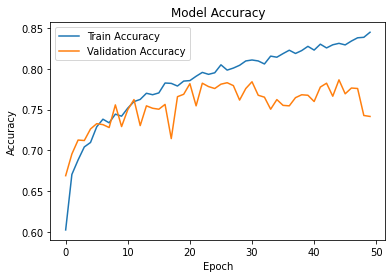

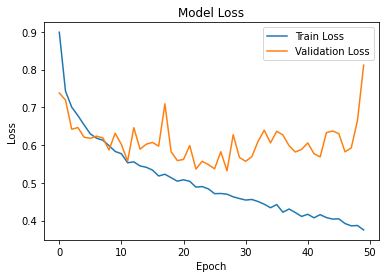

In [22]:
import matplotlib.pyplot as plt

# Plot Accuracy
# THE FIX: Changed 'acc' to 'accuracy' and 'val_acc' to 'val_accuracy'
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()

# Plot Loss (This section was already correct!)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()